<a href="https://colab.research.google.com/github/ettapranaycs24-beep/AI_LAB/blob/main/Alpha_Beta_Pruning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Input format:
  1) nested list   e.g. [[10,9],[14,18]]   (uneven branching OK)
  2) branching + leaves   e.g. branching '2 2 2', leaves '10 9 14 18 5 4 50 3'
  3) named dict   e.g. {'A': {'B': {'d1': 2, 'd2': 3}, 'C': {'f1': 0, 'f2': 1}}}
Choose format [1/2/3] (default 1): 3
Enter tree: {"R": {"X": {"M1": {"p": {"a": 21, "b": 5}, "q": {"c": 15, "d": 11}}, "M2": {"r": {"e": 12, "f": 8}, "s": {"g": 9, "h": 13}}}, "Y": {"M3": {"t": {"i": 5, "j": 12}, "u": {"k": 13, "l": 12}}, "M4": {"v": {"m": 13, "n": 14}, "w": {"o": 7, "p2": 10}}}}}
Root type MAX/MIN (default MAX): MAX
ROOT VALUE : 12
OPTIMAL PATH: R → Y → M3 → u → l
PRUNED (cut-off) subtrees: j, w
Leaves evaluated: 13 of 16


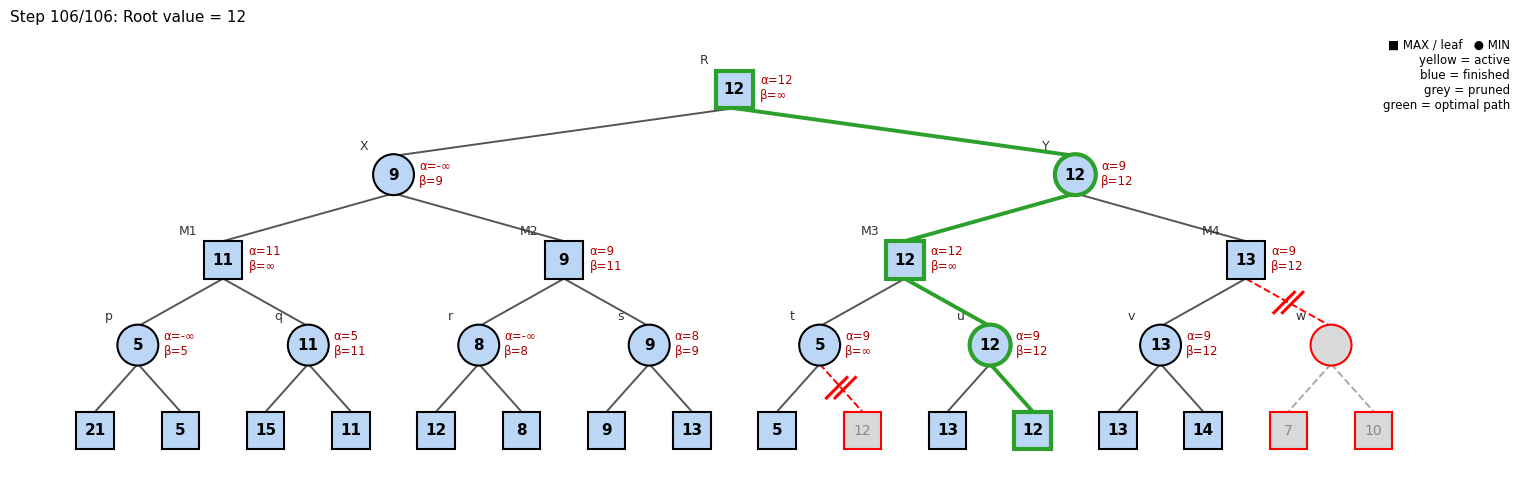

interactive(children=(IntSlider(value=0, description='Step', layout=Layout(width='80%'), max=106), Output()), …

In [2]:
import math, copy, ast
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

INF = math.inf
fmt = lambda x: "-∞" if x == -INF else "∞" if x == INF else (str(int(x)) if float(x).is_integer() else f"{x:g}")

class Node:
    def __init__(self, name=None, is_max=True, leaf=None):
        self.name, self.is_max, self.leaf = name, is_max, leaf
        self.children = []
        self.x = self.y = 0
        self.id = None

    @property
    def is_leaf(self): return self.leaf is not None

# ---------- parsing (user-defined input) ----------
def build(obj, name, is_max):
    if isinstance(obj, (int, float)):
        return Node(name, is_max, leaf=obj)
    n = Node(name, is_max)
    if isinstance(obj, dict):
        n.children = [build(v, k, not is_max) for k, v in obj.items()]
    elif isinstance(obj, (list, tuple)):
        n.children = [build(c, None, not is_max) for c in obj]
    else:
        raise ValueError(f"Unsupported node: {obj!r}")
    return n

def parse(tree, root_type="MAX"):
    is_max = root_type.upper() == "MAX"
    if isinstance(tree, dict) and len(tree) == 1 and isinstance(list(tree.values())[0], (dict, list)):
        (k, v), = tree.items()
        root = build(v, k, is_max)
    else:
        root = build(tree, None, is_max)
    nodes, leaves = [], [0]
    def layout(n, d):
        n.id = len(nodes); nodes.append(n); n.y = -d
        for c in n.children: layout(c, d + 1)
        if n.is_leaf: n.x = leaves[0]; leaves[0] += 1
        else: n.x = sum(c.x for c in n.children) / len(n.children)
    layout(root, 0)
    return root, nodes

# ---------- alpha-beta with a full trace ----------
def alpha_beta(root, nodes):
    st = {n.id: dict(status="unvisited", value=None, alpha=None, beta=None, cut=[]) for n in nodes}
    snaps, log = [], []
    label = lambda n: n.name or (f"{'MAX' if n.is_max else 'MIN'}#{n.id}" if not n.is_leaf else f"leaf {fmt(n.leaf)}")
    def snap(msg, active=None):
        snaps.append((msg, copy.deepcopy(st), active)); log.append(msg)
    def mark_pruned(n):
        st[n.id]["status"] = "pruned"
        for c in n.children: mark_pruned(c)

    def search(n, a, b):
        s = st[n.id]; s.update(status="active", alpha=a, beta=b)
        snap(f"Visit {label(n)}  (α={fmt(a)}, β={fmt(b)})", n.id)
        if n.is_leaf:
            s.update(status="done", value=n.leaf)
            snap(f"{label(n)} is terminal → value {fmt(n.leaf)}", n.id)
            return n.leaf
        v = -INF if n.is_max else INF
        for i, c in enumerate(n.children):
            cv = search(c, a, b)
            v = max(v, cv) if n.is_max else min(v, cv)
            s.update(value=v)
            snap(f"{label(n)}: child {label(c)} returned {fmt(cv)} → v={fmt(v)}", n.id)
            if n.is_max:
                if v >= b:
                    rest = n.children[i+1:]
                    for r in rest: mark_pruned(r)
                    s["cut"] = [r.id for r in rest]
                    if rest: snap(f"✂ PRUNE under {label(n)}: v={fmt(v)} ≥ β={fmt(b)} → skip {len(rest)} remaining child(ren)", n.id)
                    break
                a = max(a, v)
            else:
                if v <= a:
                    rest = n.children[i+1:]
                    for r in rest: mark_pruned(r)
                    s["cut"] = [r.id for r in rest]
                    if rest: snap(f"✂ PRUNE under {label(n)}: v={fmt(v)} ≤ α={fmt(a)} → skip {len(rest)} remaining child(ren)", n.id)
                    break
                b = min(b, v)
            s.update(alpha=a, beta=b)
            snap(f"{label(n)}: bounds updated α={fmt(a)}, β={fmt(b)}", n.id)
        s.update(status="done")
        snap(f"{label(n)} returns {fmt(v)}", n.id)
        return v

    val = search(root, -INF, INF)
    # optimal path
    path, n = [root.id], root
    while not n.is_leaf:
        nxt = next(c for c in n.children if st[c.id]["status"] == "done" and st[c.id]["value"] == st[n.id]["value"])
        path.append(nxt.id); n = nxt
    snap(f"Root value = {fmt(val)}", root.id)
    return val, path, snaps, log, st

# ---------- drawing ----------
COL = dict(unvisited="#ffffff", active="#ffe45c", done="#bcd7f5", pruned="#d9d9d9")
def draw(nodes, snaps, path, step):
    msg, st, active = snaps[step]
    final = step == len(snaps) - 1
    xs = [n.x for n in nodes]; ys = [n.y for n in nodes]
    W = max(8, (max(xs) - min(xs) + 2) * 0.9); H = max(5, (max(ys) - min(ys) - 1) * -1.9 + 2)
    fig, ax = plt.subplots(figsize=(min(W, 22), min(H, 12)))
    ax.set_aspect("equal"); ax.axis("off")
    pset = set(zip(path, path[1:]))
    # edges
    for n in nodes:
        for c in n.children:
            pr = st[c.id]["status"] == "pruned"
            on_path = final and (n.id, c.id) in pset
            ax.plot([n.x, c.x], [n.y - .22, c.y + .22], color=("red" if c.id in st[n.id]["cut"] else "#aaa") if pr else "#2ca02c" if on_path else "#555",
                    lw=2.8 if on_path else 1.4, ls="--" if pr else "-", zorder=1)
            if pr and st[n.id]["cut"] and c.id == min(st[n.id]["cut"]):
                mx, my = (n.x + c.x) / 2, (n.y + c.y) / 2
                for dx in (-.05, .05):
                    ax.plot([mx - .12 + dx, mx + .12 + dx], [my - .12, my + .12], color="red", lw=2.2, zorder=3)
    # nodes
    for n in nodes:
        s = st[n.id]; face = COL[s["status"]]
        ec = "#2ca02c" if (final and n.id in path) else "red" if s["status"] == "pruned" else "k"
        lw = 3 if (final and n.id in path) else 1.5
        if n.is_max or n.is_leaf:
            ax.add_patch(Rectangle((n.x - .22, n.y - .22), .44, .44, fc=face, ec=ec, lw=lw, zorder=2))
        else:
            ax.add_patch(Circle((n.x, n.y), .24, fc=face, ec=ec, lw=lw, zorder=2))
        if s["value"] is not None:
            ax.text(n.x, n.y, fmt(s["value"]), ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
        elif s["status"] == "pruned" and n.is_leaf:
            ax.text(n.x, n.y, fmt(n.leaf), ha="center", va="center", fontsize=10, color="#888", zorder=4)
        if n.name and not n.is_leaf:
            ax.text(n.x - .3, n.y + .3, n.name, fontsize=9, color="#333", ha="right")
        if not n.is_leaf and s["alpha"] is not None:
            ax.text(n.x + .3, n.y + .02, f"α={fmt(s['alpha'])}\nβ={fmt(s['beta'])}", fontsize=8.5, color="#a00",
                    va="center", ha="left", zorder=4, bbox=dict(fc="white", ec="none", alpha=.7, pad=.5))
    ax.set_xlim(min(xs) - 1, max(xs) + 1.6); ax.set_ylim(min(ys) - .7, max(ys) + .7)
    ax.set_title(f"Step {step}/{len(snaps)-1}: {msg}", fontsize=11, loc="left")
    ax.text(max(xs) + 1.6, max(ys) + .6,
            "■ MAX / leaf   ● MIN\nyellow = active\nblue = finished\ngrey = pruned\ngreen = optimal path",
            fontsize=8.5, va="top", ha="right")
    plt.tight_layout(); plt.show()

def solve(tree, root_type="MAX", interactive=True):
    root, nodes = parse(tree, root_type)
    val, path, snaps, log, st = alpha_beta(root, nodes)
    last = len(snaps) - 1
    pruned = [n for n in nodes if st[n.id]["status"] == "pruned" and (not any(st[p.id]["status"] == "pruned" and n in p.children for p in nodes))]
    pn = lambda n: n.name or (f"leaf {fmt(n.leaf)}" if n.is_leaf else f"{'MAX' if n.is_max else 'MIN'}#{n.id}")
    nm = lambda i: nodes[i].name or (fmt(nodes[i].leaf) if nodes[i].is_leaf else f"{'MAX' if nodes[i].is_max else 'MIN'}#{i}")
    print(f"ROOT VALUE : {fmt(val)}")
    print("OPTIMAL PATH:", " → ".join(nm(i) for i in path))
    print("PRUNED (cut-off) subtrees:", ", ".join(pn(n) for n in pruned) or "none")
    print("Leaves evaluated: %d of %d" % (sum(1 for n in nodes if n.is_leaf and st[n.id]['status'] == 'done'), sum(1 for n in nodes if n.is_leaf)))
    draw(nodes, snaps, path, last)
    if interactive:
        try:
            import ipywidgets as w
            w.interact(lambda step: draw(nodes, snaps, path, step), step=w.IntSlider(0, 0, last, 1, description="Step", layout=w.Layout(width="80%")))
        except ImportError:
            print("(pip install ipywidgets for the step slider)")
    return val, path, log

# ================= USER INPUT =================
def build_uniform(branching, leaves):
    """branching e.g. [2,2,2]; leaves = flat list of terminal values."""
    it = iter(leaves)
    def rec(d):
        return next(it) if d == len(branching) else [rec(d + 1) for _ in range(branching[d])]
    return rec(0)

print("Input format:\n  1) nested list   e.g. [[10,9],[14,18]]   (uneven branching OK)"
      "\n  2) branching + leaves   e.g. branching '2 2 2', leaves '10 9 14 18 5 4 50 3'"
      "\n  3) named dict   e.g. {'A': {'B': {'d1': 2, 'd2': 3}, 'C': {'f1': 0, 'f2': 1}}}")
choice = input("Choose format [1/2/3] (default 1): ").strip() or "1"
if choice == "2":
    br = [int(x) for x in input("Branching factor per level (space separated): ").split()]
    lv = [float(x) if "." in x else int(x) for x in input("Leaf values left→right (space separated): ").split()]
    tree = build_uniform(br, lv)
else:
    tree = ast.literal_eval(input("Enter tree: "))
rt = input("Root type MAX/MIN (default MAX): ").strip().upper() or "MAX"
_ = solve(tree, rt)